In [1]:
import pandas as pd, numpy as np, json, glob
print("Siap!")

Siap!


In [2]:
files = sorted(glob.glob("data/raw/data/*.json"))
print("Jumlah file:", len(files))
for f in files:
    print(f)

Jumlah file: 9
data/raw/data\2026-01.json
data/raw/data\2026-02.json
data/raw/data\2026-03.json
data/raw/data\2026-04.json
data/raw/data\2026-05.json
data/raw/data\2026-06.json
data/raw/data\2026-07.json
data/raw/data\2026-08.json
data/raw/data\2026-09.json


In [3]:
with open(files[-1], encoding="utf-8") as f:
    d = json.load(f)

print(d.keys())

dict_keys(['schema_version', 'report_version', 'generated_at', 'measurement_window_start', 'measurement_window_end', 'timezone', 'measurement_engine', 'total_valid_tests', 'total_excluded_tests', 'minimum_country_sample_size', 'minimum_isp_sample_size', 'methodology', 'global', 'countries', 'isps'])


In [4]:
for k, v in d.items():
    print("=====", k, "=====")
    if isinstance(v, (list, dict)):
        print(type(v).__name__, "| panjang:", len(v))
        print(json.dumps(v if isinstance(v, dict) else v[:2], indent=2)[:800])
    else:
        print(v)

===== schema_version =====
1.0
===== report_version =====
2026-09
===== generated_at =====
2026-10-04T10:24:52+00:00
===== measurement_window_start =====
2026-09-01T00:00:00+00:00
===== measurement_window_end =====
2026-10-01T00:00:00+00:00
===== timezone =====
UTC
===== measurement_engine =====
LibreSpeed
===== total_valid_tests =====
2762
===== total_excluded_tests =====
94
===== minimum_country_sample_size =====
30
===== minimum_isp_sample_size =====
20
===== methodology =====
dict | panjang: 3
{
  "percentile_method": "linear_interpolation",
  "exclusions": [
    "Rows with a missing, empty, or failed ISP lookup are excluded.",
    "A zero value for a given metric (download, upload, or ping) excludes that row from that metric's statistics only \u2014 it does not disqualify the row's other valid metrics.",
    "Country and ISP breakdowns additionally require a minimum sample size (see minimum_country_sample_size / minimum_isp_sample_size) before being published, to avoid misleadingl

In [5]:
import os
import pandas as pd

files = sorted(glob.glob("data/raw/data/*.json"))

def flat(item, extra):
    """Ratakan dict bersarang: download -> download_median, dst."""
    row = dict(extra)
    for k, v in item.items():
        if isinstance(v, dict):
            for stat, val in v.items():
                row[f"{k}_{stat}"] = val
        else:
            row[k] = v
    return row

isp_rows, country_rows = [], []
for f in files:
    bulan = os.path.basename(f).replace(".json", "")
    with open(f, encoding="utf-8") as fh:
        d = json.load(fh)
    for isp in d["isps"]:
        isp_rows.append(flat(isp, {"bulan": bulan}))
    for c in d["countries"]:
        country_rows.append(flat(c, {"bulan": bulan}))

df_isp = pd.DataFrame(isp_rows)
df_country = pd.DataFrame(country_rows)

print("df_isp     :", df_isp.shape)
print("df_country :", df_country.shape)

df_isp     : (99, 20)
df_country : (67, 18)


In [6]:
print(df_isp.columns.tolist())
print()
print("Baris ISP per bulan:")
print(df_isp["bulan"].value_counts().sort_index())
print()
print("Negara yang ada:", sorted(df_country["code"].unique()))
print()
df_isp.head()


['bulan', 'slug', 'name', 'country', 'sample_count', 'download_sample_count', 'download_average', 'download_median', 'download_p25', 'download_p75', 'upload_sample_count', 'upload_average', 'upload_median', 'upload_p25', 'upload_p75', 'ping_sample_count', 'ping_average', 'ping_median', 'ping_p25', 'ping_p75']

Baris ISP per bulan:
bulan
2026-01    14
2026-02    15
2026-03    13
2026-04    11
2026-05     5
2026-06     7
2026-07    10
2026-08    12
2026-09    12
Name: count, dtype: int64

Negara yang ada: ['AU', 'BD', 'CA', 'CL', 'CO', 'DE', 'DO', 'ES', 'FR', 'GB', 'ID', 'IN', 'IQ', 'MX', 'NL', 'PE', 'PH', 'PK', 'TR', 'US', 'VN']



,bulan,slug,name,country,sample_count,download_sample_count,download_average,download_median,download_p25,download_p75,upload_sample_count,upload_average,upload_median,upload_p25,upload_p75,ping_sample_count,ping_average,ping_median,ping_p25,ping_p75
0,2026-01,spectrum,Spectrum (Charter),US,155,153,412.79,369.36,151.76,603.75,150,42.37,29.99,12.25,39.90,155,33.95,32.0,26.00,39.50
1,2026-01,att,AT&T,US,54,52,341.35,258.63,129.94,510.02,52,218.13,151.68,29.14,357.18,54,35.52,25.5,19.25,33.75
2,2026-01,xfinity,Xfinity (Comcast),US,123,122,314.14,192.30,87.93,483.99,119,87.51,42.50,28.53,95.40,123,32.25,30.0,20.00,36.50
3,2026-01,cox,Cox,US,25,24,273.01,270.12,170.88,376.81,23,55.87,33.45,11.27,53.01,25,29.52,28.0,19.00,41.00
4,2026-01,verizon,Verizon,US,43,43,236.59,211.26,59.43,331.32,39,119.83,67.07,11.40,138.80,43,35.60,28.0,13.00,55.00


In [7]:
print(df_isp["country"].value_counts())
print()
print(df_isp[df_isp["country"] == "ID"][["bulan", "name", "sample_count", "download_median", "upload_median", "ping_median"]])


country
US    66
ID     9
MX     8
ES     5
CA     5
AU     1
VN     1
BD     1
PH     1
GB     1
IN     1
Name: count, dtype: int64

      bulan              name  sample_count  download_median  upload_median  \
11  2026-01  Telkom Indonesia           118            32.00          15.12   
12  2026-01           Indosat            41            18.77          15.09   
13  2026-01         Telkomsel            57            29.51           8.64   
26  2026-02           Indosat            20            26.58          19.96   
27  2026-02  Telkom Indonesia            57            24.46          14.34   
28  2026-02         Telkomsel            38            24.84          14.61   
40  2026-03  Telkom Indonesia            31            49.24          21.14   
41  2026-03         Telkomsel            21            26.12          11.37   
52  2026-04  Telkom Indonesia            30            29.17          12.24   

    ping_median  
11        213.5  
12         95.0  
13        213.0  
26 

In [8]:
df_isp.info()
print()
print("Missing value per kolom:")
print(df_isp.isna().sum())
print()
df_isp.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   bulan                  99 non-null     str    
 1   slug                   99 non-null     str    
 2   name                   99 non-null     str    
 3   country                99 non-null     str    
 4   sample_count           99 non-null     int64  
 5   download_sample_count  99 non-null     int64  
 6   download_average       99 non-null     float64
 7   download_median        99 non-null     float64
 8   download_p25           99 non-null     float64
 9   download_p75           99 non-null     float64
 10  upload_sample_count    99 non-null     int64  
 11  upload_average         99 non-null     float64
 12  upload_median          99 non-null     float64
 13  upload_p25             99 non-null     float64
 14  upload_p75             99 non-null     float64
 15  ping_sample_count  

,count,mean,std,min,25%,50%,75%,max
sample_count,99.0,76.303030,72.005733,20.00,30.000,46.00,96.000,333.00
download_sample_count,99.0,74.595960,70.394213,18.00,28.500,43.00,94.000,321.00
download_average,99.0,238.128687,153.548835,24.96,126.450,231.67,334.650,776.93
download_median,99.0,187.590808,154.620219,18.77,64.180,147.03,273.420,843.01
download_p25,99.0,88.577172,111.901324,1.17,24.125,61.08,104.100,775.12
download_p75,99.0,329.770404,214.383517,31.86,124.395,302.78,491.765,908.35
upload_sample_count,99.0,69.757576,64.015956,7.00,27.500,41.00,92.000,276.00
upload_average,99.0,79.467576,60.874174,8.36,34.155,65.50,112.205,397.95
upload_median,99.0,47.828384,42.997217,4.20,16.805,35.33,66.380,204.99
upload_p25,99.0,21.277071,15.687487,1.06,8.180,20.87,28.740,69.10


In [9]:
dup = df_isp.duplicated(subset=["slug", "bulan"]).sum()
print("Duplikat (slug + bulan):", dup)

# hapus jika ada
df_isp = df_isp.drop_duplicates(subset=["slug", "bulan"]).reset_index(drop=True)
print("Jumlah baris:", len(df_isp))

Duplikat (slug + bulan): 0
Jumlah baris: 99


In [10]:
for m in ["download", "upload", "ping"]:
    salah_urut = ~((df_isp[f"{m}_p25"] <= df_isp[f"{m}_median"]) &
                   (df_isp[f"{m}_median"] <= df_isp[f"{m}_p75"]))
    nol_negatif = (df_isp[f"{m}_median"] <= 0).sum()
    print(f"{m}: persentil salah urut = {salah_urut.sum()}, median <= 0 = {nol_negatif}")

download: persentil salah urut = 0, median <= 0 = 0
upload: persentil salah urut = 0, median <= 0 = 0
ping: persentil salah urut = 0, median <= 0 = 0


In [11]:
print(df_isp[["download_sample_count", "upload_sample_count", "ping_sample_count"]].describe())
print()
print("Baris dengan upload < 10 sampel :", (df_isp["upload_sample_count"] < 10).sum())
print("Baris dengan download < 10 sampel:", (df_isp["download_sample_count"] < 10).sum())


       download_sample_count  upload_sample_count  ping_sample_count
count              99.000000            99.000000          99.000000
mean               74.595960            69.757576          76.282828
std                70.394213            64.015956          72.007800
min                18.000000             7.000000          20.000000
25%                28.500000            27.500000          30.000000
50%                43.000000            41.000000          46.000000
75%                94.000000            92.000000          96.000000
max               321.000000           276.000000         333.000000

Baris dengan upload < 10 sampel : 1
Baris dengan download < 10 sampel: 0


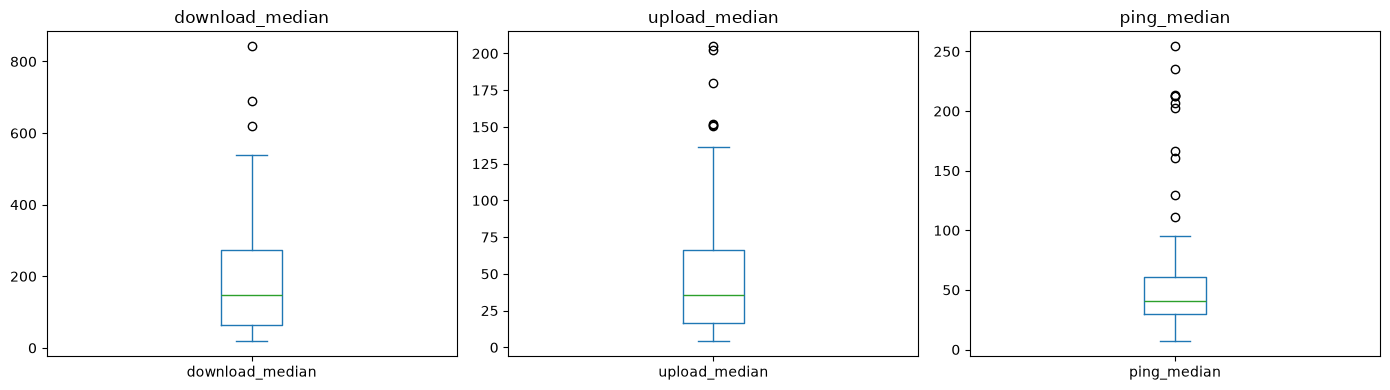

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, m in zip(ax, ["download_median", "upload_median", "ping_median"]):
    df_isp[m].plot(kind="box", ax=a, title=m)
plt.tight_layout()
plt.show()

In [13]:
sebelum = len(df_isp)
df_clean = df_isp[df_isp["upload_sample_count"] >= 10].copy().reset_index(drop=True)
print("Dibuang:", sebelum - len(df_clean), "| Sisa:", len(df_clean))

Dibuang: 1 | Sisa: 98


In [14]:
fitur_stat = [
    "download_average", "download_p25", "download_p75",
    "upload_average",   "upload_p25",   "upload_p75",
    "ping_average",     "ping_p25",     "ping_p75",
]
kolom_label = ["download_median", "upload_median", "ping_median"]

df_model = df_clean[["bulan", "name", "country", "sample_count"] + kolom_label + fitur_stat].copy()
df_model.head()

,bulan,name,country,sample_count,download_median,upload_median,ping_median,download_average,download_p25,download_p75,upload_average,upload_p25,upload_p75,ping_average,ping_p25,ping_p75
0,2026-01,Spectrum (Charter),US,155,369.36,29.99,32.0,412.79,151.76,603.75,42.37,12.25,39.90,33.95,26.00,39.50
1,2026-01,AT&T,US,54,258.63,151.68,25.5,341.35,129.94,510.02,218.13,29.14,357.18,35.52,19.25,33.75
2,2026-01,Xfinity (Comcast),US,123,192.30,42.50,30.0,314.14,87.93,483.99,87.51,28.53,95.40,32.25,20.00,36.50
3,2026-01,Cox,US,25,270.12,33.45,28.0,273.01,170.88,376.81,55.87,11.27,53.01,29.52,19.00,41.00
4,2026-01,Verizon,US,43,211.26,67.07,28.0,236.59,59.43,331.32,119.83,11.40,138.80,35.60,13.00,55.00


In [15]:
def skor(r):
    s = 0
    # download (Mbps)
    s += 2 if r.download_median >= 100 else (1 if r.download_median >= 25 else 0)
    # upload (Mbps)
    s += 2 if r.upload_median >= 20 else (1 if r.upload_median >= 5 else 0)
    # ping (ms), makin kecil makin baik
    s += 2 if r.ping_median <= 50 else (1 if r.ping_median <= 100 else 0)
    return s

def kelas(s):
    return "Baik" if s >= 5 else ("Sedang" if s >= 3 else "Buruk")

df_model["skor"] = df_model.apply(skor, axis=1)
df_model["kualitas"] = df_model["skor"].apply(kelas)

print(df_model["kualitas"].value_counts())
print()
print(df_model.groupby("country")["kualitas"].value_counts().unstack(fill_value=0))

kualitas
Baik      65
Sedang    21
Buruk     12
Name: count, dtype: int64

kualitas  Baik  Buruk  Sedang
country                      
AU           0      1       0
BD           0      1       0
CA           3      1       1
ES           5      0       0
GB           0      0       1
ID           0      8       1
IN           0      1       0
MX           3      0       5
PH           0      0       1
US          53      0      12
VN           1      0       0


In [16]:
import os
os.makedirs("data/processed", exist_ok=True)
df_model.to_csv("data/processed/isp_bersih_berlabel.csv", index=False)
print("Tersimpan:", df_model.shape)

Tersimpan: (98, 18)


In [17]:
import os
os.makedirs("data/processed", exist_ok=True)
df_model.to_csv("data/processed/isp_bersih_berlabel.csv", index=False)
print("Tersimpan:", df_model.shape)

Tersimpan: (98, 18)


In [18]:
from sklearn.model_selection import train_test_split

fitur = ["sample_count",
         "download_average", "download_p25", "download_p75",
         "upload_average",   "upload_p25",   "upload_p75",
         "ping_average",     "ping_p25",     "ping_p75"]

X = df_model[fitur]
y = df_model["kualitas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(y_test.value_counts())

Train: (78, 10) | Test: (20, 10)
kualitas
Baik      13
Sedang     4
Buruk      3
Name: count, dtype: int64


In [19]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,               # batasi agar tidak overfit dan mudah dibaca
    min_samples_leaf=3,
    class_weight="balanced",   # kompensasi kelas yang timpang
    random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

              precision    recall  f1-score   support

        Baik       1.00      1.00      1.00        13
       Buruk       1.00      0.67      0.80         3
      Sedang       0.80      1.00      0.89         4

    accuracy                           0.95        20
   macro avg       0.93      0.89      0.90        20
weighted avg       0.96      0.95      0.95        20



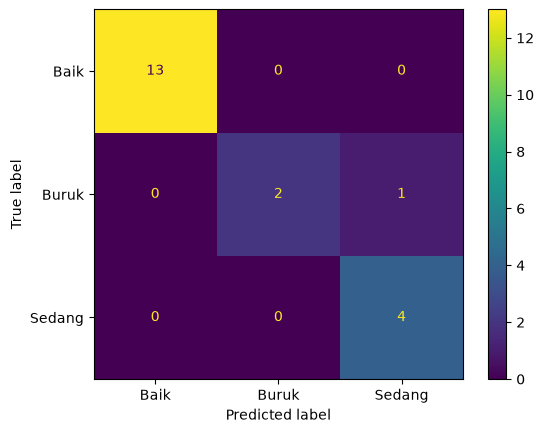

In [20]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=model.classes_),
                       display_labels=model.classes_).plot()
plt.show()

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
f1  = cross_val_score(model, X, y, cv=skf, scoring="f1_macro")
print("Akurasi CV :", acc.round(3), "| rata-rata:", acc.mean().round(3))
print("F1-macro CV:", f1.round(3),  "| rata-rata:", f1.mean().round(3))

y_cv = cross_val_predict(model, X, y, cv=skf)
print(classification_report(y, y_cv, zero_division=0))

Akurasi CV : [0.9  0.95 0.95 1.   1.  ] | rata-rata: 0.96
F1-macro CV: [0.906 0.94  0.896 1.    1.   ] | rata-rata: 0.948
              precision    recall  f1-score   support

        Baik       0.98      0.97      0.98        65
       Buruk       0.92      1.00      0.96        12
      Sedang       0.90      0.90      0.90        21

    accuracy                           0.96        98
   macro avg       0.94      0.96      0.95        98
weighted avg       0.96      0.96      0.96        98



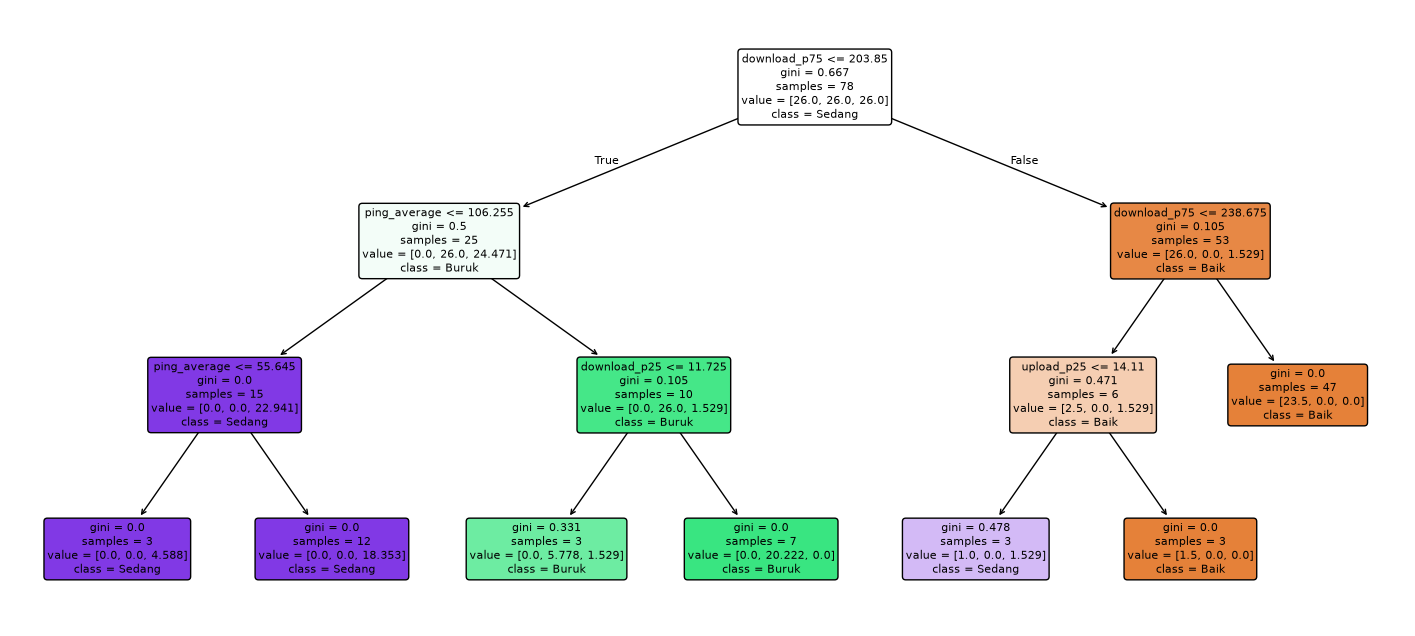

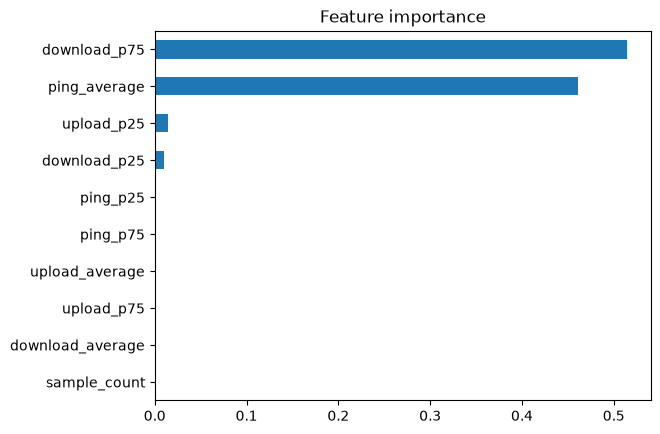

In [22]:
from sklearn.tree import plot_tree
import pandas as pd

plt.figure(figsize=(18, 8))
plot_tree(model, feature_names=fitur, class_names=model.classes_,
          filled=True, rounded=True, fontsize=8)
plt.show()

pd.Series(model.feature_importances_, index=fitur).sort_values().plot(kind="barh", title="Feature importance")
plt.show()

In [23]:
for depth in [2, 3, 4, 5, 6, None]:
    m = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=3,
                               class_weight="balanced", random_state=42)
    s = cross_val_score(m, X, y, cv=skf, scoring="f1_macro").mean()
    print(f"max_depth={depth}: F1-macro CV = {s:.3f}")

max_depth=2: F1-macro CV = 0.948
max_depth=3: F1-macro CV = 0.948
max_depth=4: F1-macro CV = 0.948
max_depth=5: F1-macro CV = 0.948
max_depth=6: F1-macro CV = 0.948
max_depth=None: F1-macro CV = 0.948


              precision    recall  f1-score   support

        Baik       1.00      1.00      1.00        13
       Buruk       1.00      0.67      0.80         3
      Sedang       0.80      1.00      0.89         4

    accuracy                           0.95        20
   macro avg       0.93      0.89      0.90        20
weighted avg       0.96      0.95      0.95        20



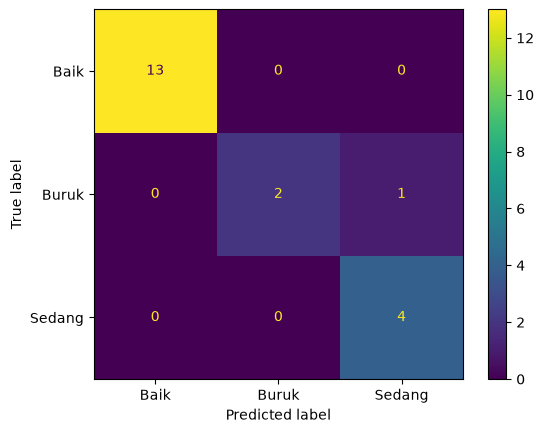

In [24]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=model.classes_),
                       display_labels=model.classes_).plot()
plt.show()

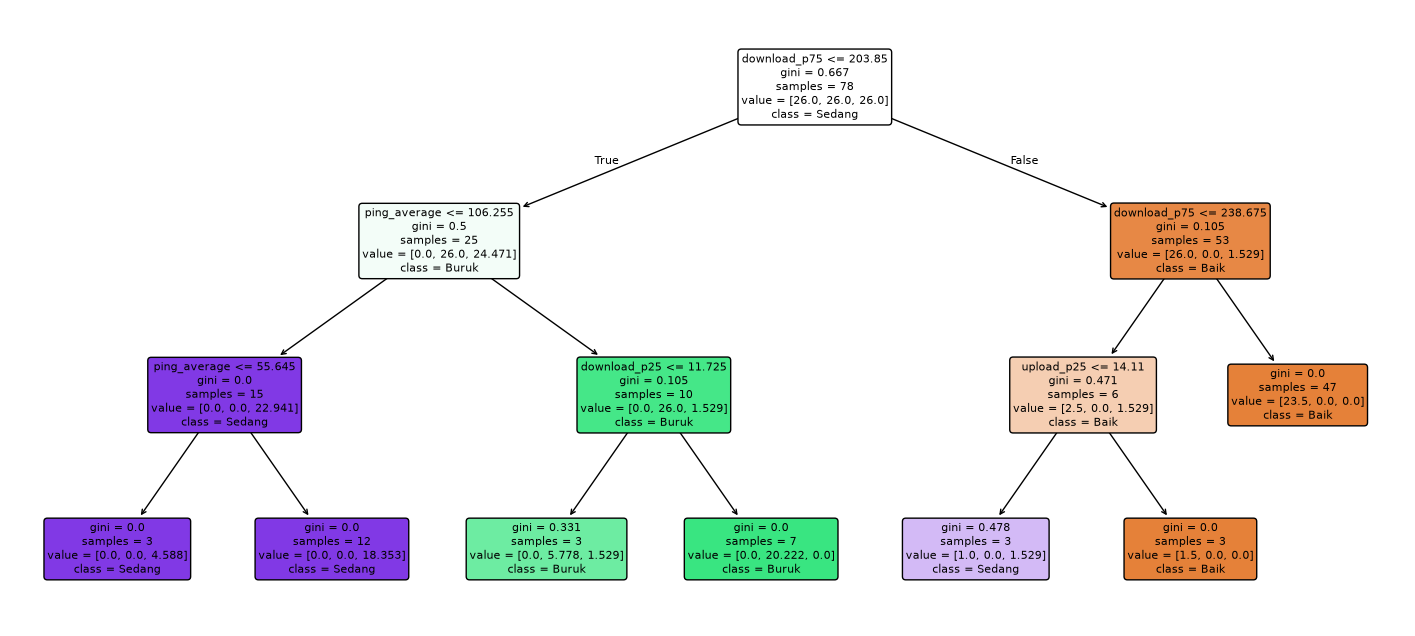

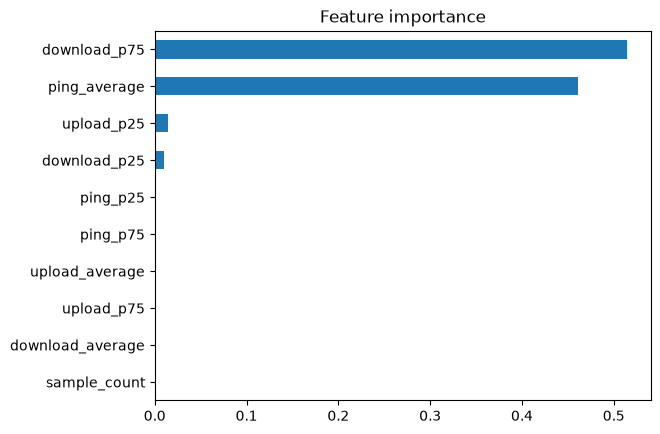

In [25]:
from sklearn.tree import plot_tree
import pandas as pd

plt.figure(figsize=(18, 8))
plot_tree(model, feature_names=fitur, class_names=model.classes_,
          filled=True, rounded=True, fontsize=8)
plt.show()

pd.Series(model.feature_importances_, index=fitur).sort_values().plot(
    kind="barh", title="Feature importance")
plt.show()

In [26]:
for depth in [2, 3, 4, 5, 6, None]:
    m = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=3,
                               class_weight="balanced", random_state=42)
    s = cross_val_score(m, X, y, cv=skf, scoring="f1_macro").mean()
    print(f"max_depth={depth}: F1-macro CV = {s:.3f}")

max_depth=2: F1-macro CV = 0.948
max_depth=3: F1-macro CV = 0.948
max_depth=4: F1-macro CV = 0.948
max_depth=5: F1-macro CV = 0.948
max_depth=6: F1-macro CV = 0.948
max_depth=None: F1-macro CV = 0.948


In [27]:
from sklearn.model_selection import GroupKFold

grup = df_model["name"]
gkf = GroupKFold(n_splits=5)

f1_g = cross_val_score(model, X, y, cv=gkf, groups=grup, scoring="f1_macro")
acc_g = cross_val_score(model, X, y, cv=gkf, groups=grup, scoring="accuracy")
print("Akurasi GroupKFold :", acc_g.round(3), "| rata-rata:", acc_g.mean().round(3))
print("F1-macro GroupKFold:", f1_g.round(3),  "| rata-rata:", f1_g.mean().round(3))

Akurasi GroupKFold : [1.    0.95  1.    0.842 0.895] | rata-rata: 0.937
F1-macro GroupKFold: [1.    0.937 1.    0.587 0.926] | rata-rata: 0.89


In [28]:
for i, (tr, te) in enumerate(gkf.split(X, y, groups=grup), 1):
    print(f"Fold {i}: ISP uji = {sorted(grup.iloc[te].unique())}")
    print(y.iloc[te].value_counts().to_dict())

Fold 1: ISP uji = ['CenturyLink', 'Cox', 'Jio', 'Viettel', 'Xfinity (Comcast)']
{'Baik': 18, 'Sedang': 1, 'Buruk': 1}
Fold 2: ISP uji = ['EE', 'Frontier', 'Rogers', 'Totalplay', 'Verizon']
{'Baik': 14, 'Sedang': 6}
Fold 3: ISP uji = ['Bell Canada', 'Movistar (Telefónica)', 'Southern Phone', 'Spectrum (Charter)', 'Telkomsel', 'Telmex (UNINET)']
{'Baik': 11, 'Buruk': 5, 'Sedang': 4}
Fold 4: ISP uji = ['AT&T', 'Indosat', 'Optimum', 'PLDT', 'Telkom Indonesia']
{'Baik': 12, 'Buruk': 5, 'Sedang': 2}
Fold 5: ISP uji = ['Orange Spain', 'Starlink', 'T-Mobile', 'Vodafone Spain', 'Windstream Communication (Bangladesh)']
{'Baik': 10, 'Sedang': 8, 'Buruk': 1}


In [29]:
for i, (tr, te) in enumerate(gkf.split(X, y, groups=grup), 1):
    print(f"Fold {i}: ISP uji = {sorted(grup.iloc[te].unique())}")
    print(y.iloc[te].value_counts().to_dict())

Fold 1: ISP uji = ['CenturyLink', 'Cox', 'Jio', 'Viettel', 'Xfinity (Comcast)']
{'Baik': 18, 'Sedang': 1, 'Buruk': 1}
Fold 2: ISP uji = ['EE', 'Frontier', 'Rogers', 'Totalplay', 'Verizon']
{'Baik': 14, 'Sedang': 6}
Fold 3: ISP uji = ['Bell Canada', 'Movistar (Telefónica)', 'Southern Phone', 'Spectrum (Charter)', 'Telkomsel', 'Telmex (UNINET)']
{'Baik': 11, 'Buruk': 5, 'Sedang': 4}
Fold 4: ISP uji = ['AT&T', 'Indosat', 'Optimum', 'PLDT', 'Telkom Indonesia']
{'Baik': 12, 'Buruk': 5, 'Sedang': 2}
Fold 5: ISP uji = ['Orange Spain', 'Starlink', 'T-Mobile', 'Vodafone Spain', 'Windstream Communication (Bangladesh)']
{'Baik': 10, 'Sedang': 8, 'Buruk': 1}


|--- download_p75 <= 203.85
|   |--- ping_average <= 106.25
|   |   |--- class: Sedang
|   |--- ping_average >  106.25
|   |   |--- class: Buruk
|--- download_p75 >  203.85
|   |--- download_p75 <= 238.68
|   |   |--- class: Baik
|   |--- download_p75 >  238.68
|   |   |--- class: Baik



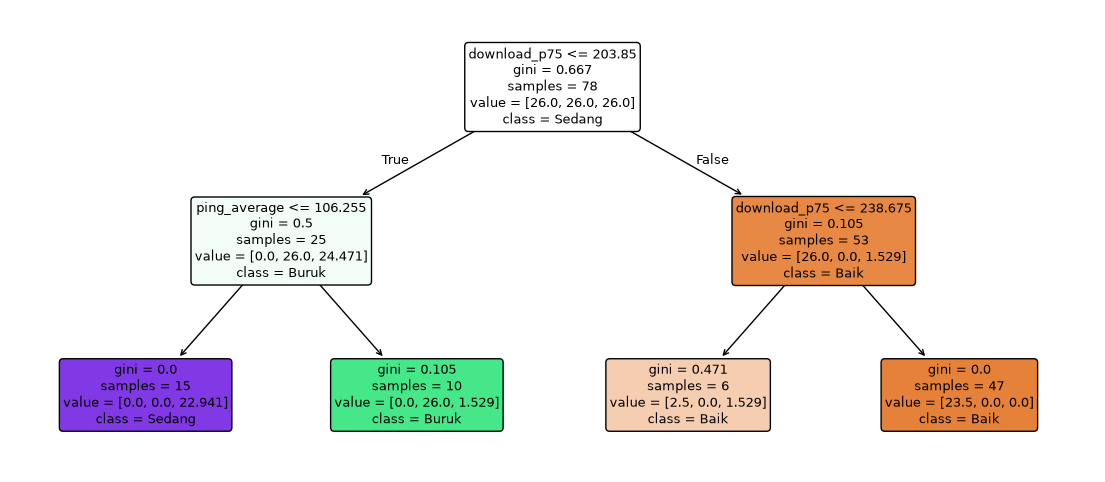

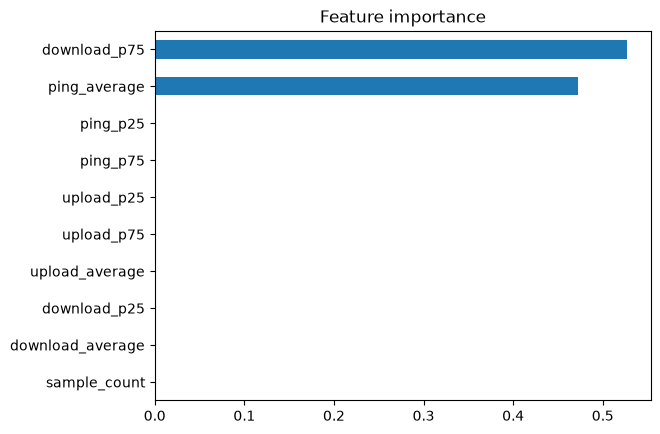

              precision    recall  f1-score   support

        Baik       1.00      1.00      1.00        13
       Buruk       1.00      0.67      0.80         3
      Sedang       0.80      1.00      0.89         4

    accuracy                           0.95        20
   macro avg       0.93      0.89      0.90        20
weighted avg       0.96      0.95      0.95        20



In [30]:
from sklearn.tree import export_text, plot_tree
import pandas as pd

model_final = DecisionTreeClassifier(
    max_depth=2, min_samples_leaf=3,
    class_weight="balanced", random_state=42)
model_final.fit(X_train, y_train)

# aturan dalam bentuk teks
print(export_text(model_final, feature_names=fitur))

# gambar pohon
plt.figure(figsize=(14, 6))
plot_tree(model_final, feature_names=fitur, class_names=model_final.classes_,
          filled=True, rounded=True, fontsize=9)
plt.show()

# fitur penting
pd.Series(model_final.feature_importances_, index=fitur).sort_values().plot(
    kind="barh", title="Feature importance")
plt.show()

# evaluasi akhir di data uji
print(classification_report(y_test, model_final.predict(X_test), zero_division=0))

In [ ]:
import os
os.makedirs("data/processed", exist_ok=True)
df_model.to_csv("data/processed/isp_bersih_berlabel.csv", index=False)

: 

In [1]:
import os
os.makedirs("data/processed", exist_ok=True)
df_model.to_csv("data/processed/isp_bersih_berlabel.csv", index=False)
print("Tersimpan:", df_model.shape)


NameError: name 'df_model' is not defined